# S4 NLL figures: Fig. 6 C-I and Supplementary Fig. S8 A-E

Draws every S4 panel from **one file**, `s4_figure_data.pkl`, written by
`s4_nll_build_data.ipynb`. No wavs, model outputs or cluster paths are needed here.

| Panel | What it shows | Section | Output file |
|---|---|---|---|
| Fig. 6C | Condition effect on NLL, both species | 3 | `s4_condition_effect_forest.png` |
| Fig. 6D | NLL across position within a syllable, one panel per species | 4 | `s4_syllabletrace_byspecies.png` |
| Fig. 6 E-F | Syllable boundary vs interior | 4 | `s4_boundaryinterior_bothspecies_boxplot.png` |
| Fig. 6G | Zebra finch intro vs non-intro notes | 5 | `zf_intro_nonintro_nll_ratio_combined.png` |
| Fig. 6H | Starling inside vs outside k-grams, k = 5 | 6 | `q3_kgram_inside_outside_nll_combined_k5.png` |
| Fig. 6I | Condition effect before and after each covariate | 7 | `s4_all_confounds_mediation_sharedbaseline.png` |
| S8 A-B | Silence vs song | 8 | `s4_silencesong_bothspecies_boxplot.png` |
| S8 C-D | Peak song NLL and NLL jump rate | 9 | `s4_heliox_maxNLL_jumprate_vertical_leveladj.png` |
| S8E | Inside vs outside k-grams, k = 3 to 8 | 6 | `q3_kgram_inside_outside_nll_combined_k3to6.png` |

If the figures are renumbered, this table is the only place the panel letters live.
Fig. 6 A-B (example traces) are not made here.

**Sign convention.** Condition effects are reported as Regair minus Heliox, so a negative
value means NLL is higher under heliox. The exception is Fig. 6I, plotted as Heliox minus
Regair, as in the manuscript.

**Section 10** collects every statistic into one table, saves it and prints it.

**Run order:** top to bottom. A cell that records statistics first clears what its earlier runs
recorded, so rerunning one cell and then Section 10 gives an up-to-date table.

## 1. Setup

In [1]:
# Cell 1: paths
import os

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
FIG_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
BUNDLE_PATH = os.path.join(DATA_DIR, 's4_figure_data.pkl')
os.makedirs(FIG_DIR, exist_ok=True)
FIG_DPI = 500
print('data   :', BUNDLE_PATH)
print('figures:', os.path.abspath(FIG_DIR))

data   : /mnt/cube/lstanwic/umap_avgn_shared/lauren_umap/heliox_processing/notebooks/for_github/data/s4_figure_data.pkl
figures: /mnt/cube/lstanwic/umap_avgn_shared/lauren_umap/heliox_processing/notebooks/for_github/figures


In [2]:
# Cell 2: imports, figure style, shared helpers
import pickle, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 16, 'axes.linewidth': 1.4,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.major.width': 1.4, 'ytick.major.width': 1.4,
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.labelsize': 15, 'ytick.labelsize': 15, 'axes.labelsize': 17,
})

# Pale fills are for boxplots, dark for line traces. Separate names, so no panel's colors
# depend on the order cells were run in.
REGAIR_COLOR,      HELIOX_COLOR      = '#E2DDF5', '#D9F6DC'
REGAIR_COLOR_DARK, HELIOX_COLOR_DARK = 'darkmagenta', 'forestgreen'

SPECIES_LABELS = {'starling': 'Starling', 'zebra_finch': 'Zebra finch'}
SPECIES_COLORS     = {'starling': '#ABABAB', 'zebra_finch': '#768393'}  # condition-effect panel
MED_SPECIES_COLORS = {'starling': '#ABABAB', 'zebra_finch': '#2874A6'}  # covariate panel
PANEL_COLORS       = {'starling': '#8C8C8C', 'zebra_finch': '#3F6FA6'}  # peak NLL / jump rate
PALE = {'regair': '#D9D2E9', 'heliox': '#D0E8D0'}                      # ratio panels: lavender / pale green
DARK = {'regair': 'darkmagenta', 'heliox': 'forestgreen'}              # k-gram sweep
COND_ORDER = ['regair', 'heliox']
CONDITION_KEY = 'C(condition, Treatment(reference="regair"))[T.heliox]'


# Two star conventions are used in the assembled figure and both are needed.
# sig_marker goes to **** and falls back to 'ns' (boxplots, condition effect, covariates, intro).
# p_to_stars goes to **** and falls back to '' (k-gram and jump-rate panels).
def sig_marker(p):
    return '****' if p < 1e-4 else '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'

def p_to_stars(p):
    if not np.isfinite(p):
        return ''
    return '****' if p < 1e-4 else '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 5e-2 else ''


RATIO_TICKS = np.array([0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95,
                        1.0, 1.05, 1.1, 1.15, 1.2, 1.25, 1.3, 1.4, 1.5, 1.75, 2.0, 2.5,
                        3.0, 4.0, 5.0, 7.0, 10.0])


def set_ratio_ticks(ax, max_ticks=8):
    """Readable ticks on a log-scaled ratio axis. Call last, after the final y-limits
    are set, since it reads them."""
    lo, hi = ax.get_ylim()
    t = RATIO_TICKS[(RATIO_TICKS >= lo) & (RATIO_TICKS <= hi)]
    if len(t) < 3:
        # range too narrow for the standard ratio ticks (effects near 1.0)
        t = np.linspace(lo, hi, 5)
        ax.set_yticks(t)
        ax.set_yticklabels([f'{v:.3f}' for v in t])
        ax.yaxis.set_minor_locator(mticker.NullLocator())
        return
    if len(t) > max_ticks:
        step = int(np.ceil(len(t) / max_ticks))
        keep = set(t[::step]) | {1.0}
        t = np.array(sorted(v for v in t if v in keep))
    ax.set_yticks(t)
    ax.set_yticklabels([f'{v:g}' for v in t])
    ax.yaxis.set_minor_locator(mticker.NullLocator())


def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=FIG_DPI, transparent=True, bbox_inches='tight')


# ---- model fitting: quiet, but nothing is hidden ---------------------------------------------
# statsmodels prints a boundary warning whenever a bird random-intercept variance is
# estimated at zero. Those warnings are silenced here and logged instead, so Section 10 can
# list exactly which fits were affected.
FIT_LOG = []


def fit_lme(formula, data, groups, label, **fit_kwargs):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fit = smf.mixedlm(formula, data, groups=groups).fit(**fit_kwargs)
    FIT_LOG.append(dict(model=label, converged=bool(fit.converged),
                        bird_variance=float(fit.cov_re.iloc[0, 0]), n_obs=len(data)))
    return fit


# ---- every reported number is collected here and checked in Section 10 -------------------------
STATS = []


def record(panel, species, quantity, **fields):
    STATS.append(dict(panel=panel, species=species, quantity=quantity, **fields))


def start_panel(*panels, fits=None):
    """Forget what earlier runs recorded for these panels. Called at the top of every cell that records,
    so rerunning a cell replaces its rows in the statistics table. Without this, a rerun adds duplicate
    rows, and rows from an older version of the cell (an old covariate, say) stay in the table.
    `fits` names the fit-log entries to clear, by the start of their label; the panel names by default."""
    STATS[:] = [r for r in STATS if r['panel'] not in panels]
    prefixes = tuple(panels if fits is None else fits)
    FIT_LOG[:] = [r for r in FIT_LOG if not r['model'].startswith(prefixes)]


import sys, scipy, statsmodels
# The k-gram models sit on the boundary of the parameter space (see Section 10), where the
# last digits of SE and P can depend on the statsmodels version, so the versions are printed.
print('python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scipy', scipy.__version__, '| statsmodels', statsmodels.__version__, '| matplotlib', mpl.__version__)

python 3.8.8 | numpy 1.22.4 | pandas 1.5.3 | scipy 1.10.1 | statsmodels 0.14.1 | matplotlib 3.7.5


## 2. Load the data

In [3]:
# Cell 3: load the pickle and show what is in it
class _NumpyCompatUnpickler(pickle.Unpickler):
    """Redirects numpy._core.* <-> numpy.core.* during unpickling, so a file saved under
    one numpy major version opens under the other."""
    def find_class(self, module, name):
        if module.startswith('numpy._core'):
            module = module.replace('numpy._core', 'numpy.core', 1)
        elif module.startswith('numpy.core'):
            alt = module.replace('numpy.core', 'numpy._core', 1)
            try:
                return super().find_class(alt, name)
            except ModuleNotFoundError:
                pass
        return super().find_class(module, name)


with open(BUNDLE_PATH, 'rb') as f:
    try:
        D = pickle.load(f)
    except ModuleNotFoundError:
        f.seek(0)
        D = _NumpyCompatUnpickler(f).load()

meta = D['meta']
print(f"built {meta['created']} by {meta['built_by']} ({meta['audio_tables']})")
for message in meta.get('incomplete_tables', []):
    print('[INCOMPLETE]', message)
bird_cols = {'region_nll': 'bird_uid', 'boundary_nll': 'bird_uid', 'song_covariates': 'bird_uid',
             'starling_syllable_nll': 'bird', 'zf_syllable_nll': 'bird_id', 'song_trace_metrics': 'bird_uid'}
for name, obj in D.items():
    if isinstance(obj, pd.DataFrame):
        birds = f"{obj[bird_cols[name]].nunique()} birds" if name in bird_cols else ''
        print(f'  {name:24s} {len(obj):>8d} rows  {birds}')
print(f"  {'starling_kgram_sets':24s} {len(D['starling_kgram_sets']):>8d} sets")

# categories were only a storage saving; plain strings behave the same on every pandas version
for name in ['region_nll', 'boundary_nll', 'syllable_position_nll']:
    for c in D[name].columns:
        if str(D[name][c].dtype) == 'category':
            D[name][c] = D[name][c].astype(str)

built 2026-10-11T11:08:53 by s4_nll_build_data.ipynb (reused from s4_figure_cache)
  region_nll                   4188 rows  12 birds
  boundary_nll               137922 rows  12 birds
  syllable_position_nll     1380720 rows  
  song_covariates              2094 rows  12 birds
  starling_syllable_nll       28057 rows  6 birds
  zf_syllable_nll             34051 rows  6 birds
  song_trace_metrics           2094 rows  12 birds
  starling_kgram_sets            60 sets


## 3. Condition effect on NLL (Fig. 6C)

`nll ~ condition + (1 | bird)`, fit separately per species on song and silence
observations together.

Zebra finch: β=-0.2284, SE=0.0370, z=-6.18, P=6.391e-10
Starling: β=-0.0699, SE=0.0163, z=-4.28, P=1.827e-05


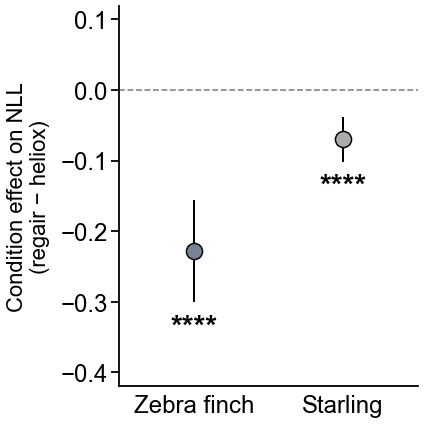

In [4]:
# Cell 4: Fig. 6C
FS_TICK, FS_YLABEL, FS_SIG = 24, 22, 30   # font sizes in one place

start_panel('Fig 6C')
forest_rows = []
for sp in ['zebra_finch', 'starling']:
    sub = D['region_nll'][D['region_nll']['species'] == sp]
    r = fit_lme('nll ~ C(condition, Treatment(reference="regair"))', sub, sub['bird_uid'],
                f'Fig 6C {sp}')
    # the model is fit heliox - regair; negated here so the table is in the paper's
    # regair - heliox convention. SE and P are unaffected by the sign flip.
    row = dict(beta=-r.params[CONDITION_KEY], se=r.bse[CONDITION_KEY],
               z=-r.tvalues[CONDITION_KEY], p=r.pvalues[CONDITION_KEY])
    forest_rows.append(dict(species=sp, row=SPECIES_LABELS[sp], color=SPECIES_COLORS[sp], **row))
    record('Fig 6C', sp, 'condition effect', n_obs=len(sub), n_birds=sub['bird_uid'].nunique(), **row)
forest_df = pd.DataFrame(forest_rows)
for row in forest_df.itertuples():
    print(f'{row.row}: β={row.beta:.4f}, SE={row.se:.4f}, z={row.z:.2f}, P={row.p:.3e}')

fig, ax = plt.subplots(figsize=(6, 6))
x = np.arange(len(forest_df)) * 1.2
# the y extent is computed up front so the star offset scales with the data range
y_lo = (forest_df['beta'] - 1.96 * forest_df['se']).min()
y_hi = (forest_df['beta'] + 1.96 * forest_df['se']).max()
y_range = (y_hi - y_lo) or 1.0
SIG_OFFSET = 0.06 * y_range
for xi, row in zip(x, forest_df.itertuples()):
    ax.errorbar(xi, row.beta, yerr=1.96 * row.se, fmt='none', ecolor='black',
                elinewidth=2.0, capsize=0, zorder=2)
    ax.scatter(xi, row.beta, s=260, color=row.color, edgecolor='black', linewidth=1.5, zorder=3)
    # stars sit outside the CI on whichever side the estimate falls
    if row.beta >= 0:
        ax.text(xi, row.beta + 1.96 * row.se + SIG_OFFSET, sig_marker(row.p),
                ha='center', va='bottom', fontsize=FS_SIG, fontweight='bold')
    else:
        ax.text(xi, row.beta - 1.96 * row.se - SIG_OFFSET, sig_marker(row.p),
                ha='center', va='top', fontsize=FS_SIG, fontweight='bold')
ax.axhline(0, color='gray', linestyle='--', linewidth=1.6, zorder=1)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_linewidth(1.8)
ax.spines['bottom'].set_linewidth(1.8)
ax.set_xticks(x)
ax.set_xticklabels(forest_df['row'], fontsize=FS_TICK)
ax.tick_params(axis='x', length=0, pad=8)
ax.tick_params(axis='y', labelsize=FS_TICK, width=1.8, length=8)
ax.set_xlim(x.min() - 0.6, x.max() + 0.6)
ax.set_ylim(min(0, y_lo) - y_range * 0.45, max(0, y_hi) + y_range * 0.45)
ax.set_ylabel('Condition effect on NLL\n(regair − heliox)', fontsize=FS_YLABEL, labelpad=10)
plt.tight_layout()
savefig(fig, 's4_condition_effect_forest.png')
plt.show()

## 4. Within the syllable (Fig. 6 D-F)

20 position bins; each line is a mean over this many birds:
condition    heliox  regair
species                    
starling          6       6
zebra_finch       6       6


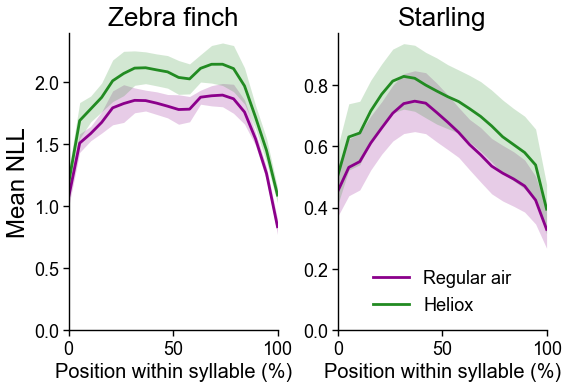

In [5]:
# Cell 5: Fig. 6D, mean NLL across normalized position in the syllable, one panel per species
# Baseline NLL differs about two-fold between the species, so they are not pooled.
BIRD_COL = 'bird_uid'
pos = D['syllable_position_nll']
if BIRD_COL in pos.columns:
    # one profile per bird, then the birds are averaged: a bird with many syllables counts no
    # more than one with few, and the band is +/- 1 SEM across birds
    per_bird = pos.groupby(['species', BIRD_COL, 'condition', 'bin'], observed=True)['nll'].mean().reset_index()
    profile = per_bird.groupby(['species', 'condition', 'bin'])['nll'].agg(['mean', 'sem', 'count'])
    unit = 'birds'
else:
    # the table does not say which bird a syllable came from, so every syllable counts once and
    # the band is +/- 1 SEM across syllables
    profile = pos.groupby(['species', 'condition', 'bin'], observed=True)['nll'].agg(['mean', 'sem', 'count'])
    unit = 'syllables'
profile = profile.reset_index()
print(f"{pos['bin'].nunique()} position bins; each line is a mean over this many {unit}:")
print(profile.groupby(['species', 'condition'])['count'].first().unstack().to_string())

fig, axes = plt.subplots(1, 2, figsize=(8, 5.5), sharey=False)
for ax, sp in zip(axes, ['zebra_finch', 'starling']):
    for condition, color in [('regair', REGAIR_COLOR_DARK), ('heliox', HELIOX_COLOR_DARK)]:
        sub = profile[(profile['species'] == sp) & (profile['condition'] == condition)].sort_values('bin')
        x_pct = np.linspace(0, 100, len(sub))
        ax.plot(x_pct, sub['mean'], color=color, linewidth=2.8,
                label='Heliox' if condition == 'heliox' else 'Regular air')
        ax.fill_between(x_pct, sub['mean'] - sub['sem'], sub['mean'] + sub['sem'],
                        alpha=0.2, color=color, linewidth=0)
    ax.set_title(SPECIES_LABELS[sp], fontsize=26, pad=8)
    ax.set_xlabel('Position within syllable (%)', fontsize=20)
    ax.set_xlim(0, 100)
    ax.set_ylim(bottom=0)
    ax.tick_params(axis='both', labelsize=18)
axes[0].set_ylabel('Mean NLL', fontsize=24)
axes[1].legend(frameon=False, fontsize=18, loc='lower center')
plt.tight_layout()
savefig(fig, 's4_syllabletrace_byspecies.png')
plt.show()

In [6]:
# Cell 6: region x condition model and boxplot, shared by Fig. 6 E-F and S8 A-B
# Model: nll ~ region * condition + (1 | bird), fit separately per species.
# It is fit three times with different reference levels, because the four brackets are
# simple effects that one parameterization does not expose directly.
def fit_region_condition(df, region_ref, condition_ref, label):
    return fit_lme(f'nll ~ C(region, Treatment(reference="{region_ref}")) * '
                   f'C(condition, Treatment(reference="{condition_ref}"))',
                   df, df['bird_uid'], label)


def region_condition_contrasts(df, regions, label):
    """regions = (reference, other). Returns the four bracket P values, plus the heliox
    effect within each region as (beta, se, z, p) in regair - heliox convention."""
    ref, other = regions
    region_key = f'C(region, Treatment(reference="{ref}"))[T.{other}]'
    r_ref = fit_region_condition(df, ref, 'regair', f'{label}: reference {ref}, regair')
    r_hel = fit_region_condition(df, ref, 'heliox', f'{label}: reference {ref}, heliox')
    r_oth = fit_region_condition(df, other, 'regair', f'{label}: reference {other}, regair')
    pvals = dict(region_p=r_ref.pvalues[region_key],               # region difference in regair
                 region_p_heliox=r_hel.pvalues[region_key],        # region difference in heliox
                 condition_p=r_ref.pvalues[CONDITION_KEY],         # heliox effect in the reference region
                 condition_p_song=r_oth.pvalues[CONDITION_KEY])    # heliox effect in the other region
    effects = {reg: dict(beta=-r.params[CONDITION_KEY], se=r.bse[CONDITION_KEY],
                         z=-r.tvalues[CONDITION_KEY], p=r.pvalues[CONDITION_KEY])
               for reg, r in [(ref, r_ref), (other, r_oth)]}
    return pvals, effects


def plot_region_condition_boxplot(ax, df, pvals, region_labels, x_spacing=1.0, box_width=0.5):
    groups = [(region_labels[0], 'regair'), (region_labels[1], 'regair'),
              (region_labels[0], 'heliox'), (region_labels[1], 'heliox')]
    labels = [f'Regair\n{region_labels[0]}', f'Regair\n{region_labels[1]}',
              f'Heliox\n{region_labels[0]}', f'Heliox\n{region_labels[1]}']
    colors = [REGAIR_COLOR, REGAIR_COLOR, HELIOX_COLOR, HELIOX_COLOR]
    box_data = [df.loc[(df['region'] == r) & (df['condition'] == c), 'nll'].values for r, c in groups]

    # only the spacing scales with x_spacing; box width stays fixed, so the two figures keep
    # identical box geometry despite needing different group separations
    x = np.arange(4) * x_spacing
    bp = ax.boxplot(box_data, positions=x, widths=box_width, patch_artist=True,
                    showfliers=False, medianprops={'color': 'black', 'linewidth': 1.4},
                    whiskerprops={'linewidth': 1.2}, capprops={'linewidth': 1.2})
    for patch, c in zip(bp['boxes'], colors):
        patch.set_facecolor(c); patch.set_alpha(0.65)
        patch.set_edgecolor('black'); patch.set_linewidth(1.0)
    ax.set_xlim(x.min() - 0.5, x.max() + 0.5)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=21)
    ax.tick_params(axis='y', labelsize=18)

    # brackets are placed off the whisker caps, not the raw data, so they clear the boxes
    cap_ys = [cap.get_ydata()[0] for cap in bp['caps']]
    y_max, y_min = max(cap_ys), min(cap_ys)
    y_range = y_max - y_min
    brackets = [(x[0], x[1], pvals['region_p']), (x[2], x[3], pvals['region_p_heliox']),
                (x[0], x[2], pvals['condition_p']), (x[1], x[3], pvals['condition_p_song'])]
    plotted_max = y_max
    for (x1, x2, p), h in zip(brackets, [y_max + y_range * f for f in (0.12, 0.12, 0.28, 0.46)]):
        ax.plot([x1, x1, x2, x2], [h, h + y_range * 0.01, h + y_range * 0.01, h],
                color='black', linewidth=1.6)
        ax.text((x1 + x2) / 2, h + y_range * 0.03, sig_marker(p), ha='center', fontsize=20)
        plotted_max = max(plotted_max, h)
    ax.set_ylim(top=plotted_max + y_range * 0.2)


def region_condition_figure(table, regions, panel, x_spacing, filename):
    start_panel(panel)
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=False)
    for ax, sp in zip(axes, ['starling', 'zebra_finch']):
        sub = table[table['species'] == sp]
        pvals, effects = region_condition_contrasts(sub, regions, f'{panel} {sp}')
        plot_region_condition_boxplot(ax, sub, pvals, region_labels=list(regions), x_spacing=x_spacing)
        ax.set_title(SPECIES_LABELS[sp], fontsize=28, pad=2)
        print(f'--- {SPECIES_LABELS[sp]} ---')
        for reg, e in effects.items():
            record(panel, sp, f'condition effect, {reg}', n_obs=len(sub),
                   n_birds=sub['bird_uid'].nunique(), **e)
            print(f'  heliox effect in {reg:8s}: β={e["beta"]:.4f}, SE={e["se"]:.4f}, '
                  f'z={e["z"]:.2f}, P={e["p"]:.3e}')
        print(f'  {regions[1]} vs {regions[0]}: regair P={pvals["region_p"]:.3e}, '
              f'heliox P={pvals["region_p_heliox"]:.3e}')
    axes[0].set_ylabel('NLL', fontsize=24)      # the boxes show the observed values, not model predictions
    plt.tight_layout()
    savefig(fig, filename)
    plt.show()

--- Starling ---
  heliox effect in boundary: β=-0.0219, SE=0.0046, z=-4.75, P=2.013e-06
  heliox effect in interior: β=-0.1146, SE=0.0046, z=-24.87, P=1.591e-136
  interior vs boundary: regair P=9.098e-199, heliox P=0.000e+00
--- Zebra finch ---
  heliox effect in boundary: β=-0.1801, SE=0.0051, z=-35.09, P=8.431e-270
  heliox effect in interior: β=-0.3260, SE=0.0051, z=-63.53, P=0.000e+00
  interior vs boundary: regair P=0.000e+00, heliox P=0.000e+00


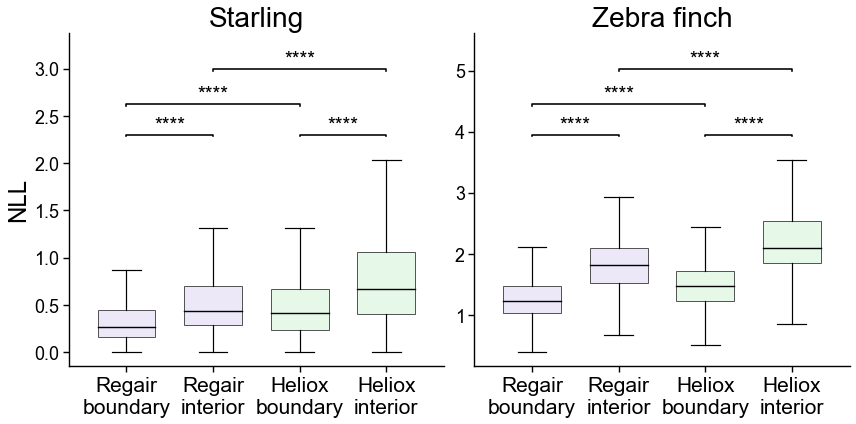

In [7]:
# Cell 7: Fig. 6 E-F, syllable boundary (first 10 ms) vs interior
region_condition_figure(D['boundary_nll'], ('boundary', 'interior'), 'Fig 6 E-F',
                        x_spacing=0.75, filename='s4_boundaryinterior_bothspecies_boxplot.png')

## 5. Zebra finch intro notes (Fig. 6G)

Syllable NLL and gap NLL are stacked, then averaged to one intro value and one non-intro
value per song before fitting, so songs with many syllables cannot dominate. The model is
on log NLL, so the coefficient exponentiates to an intro / non-intro ratio.

In [8]:
# Cell 8: per-song intro and non-intro means, ratio models
start_panel('Fig 6G')
zf = D['zf_syllable_nll'].copy()
zf['is_heliox'] = (zf['condition'] == 'heliox').astype(int)
zf['is_intro_num'] = zf['is_intro'].astype(int)

_id = ['bird_id', 'song_id', 'condition', 'is_intro_num', 'is_heliox']
zf_stack = pd.concat([zf[_id].assign(value=zf['interior_nll']),
                      zf[_id].assign(value=zf['gap_nll'])],
                     ignore_index=True).dropna(subset=['value'])

song_rows = []
for (bird_id, condition, song_id), g in zf_stack.groupby(['bird_id', 'condition', 'song_id'],
                                                         sort=False, observed=True):
    intro = g.loc[g['is_intro_num'] == 1, 'value'].dropna()
    nonintro = g.loc[g['is_intro_num'] == 0, 'value'].dropna()
    if len(intro) < 1 or len(nonintro) < 1:
        continue                      # a song needs both kinds of note to give a ratio
    song_rows.append(dict(bird_id=bird_id, condition=condition, song_id=song_id,
                          is_intro=1, value=intro.mean(), n=len(intro)))
    song_rows.append(dict(bird_id=bird_id, condition=condition, song_id=song_id,
                          is_intro=0, value=nonintro.mean(), n=len(nonintro)))
zf_per_song = pd.DataFrame(song_rows)
n_songs = zf_per_song['song_id'].nunique()
zf_per_song = zf_per_song[zf_per_song['value'] > 0].copy()        # log needs positive values
zf_per_song['log_value'] = np.log(zf_per_song['value'])
zf_per_song['is_heliox'] = (zf_per_song['condition'] == 'heliox').astype(int)
print(f'{n_songs} songs with both intro and non-intro notes')
record('Fig 6G', 'zebra_finch', 'songs with intro and non-intro notes', value=n_songs)

intro_rows = []
for cond in COND_ORDER:
    d = zf_per_song[zf_per_song['condition'] == cond]
    m = fit_lme('log_value ~ is_intro', d, d['bird_id'].astype(str), f'Fig 6G {cond}',
                reml=False, method='lbfgs', disp=False)
    b, se = m.params['is_intro'], m.bse['is_intro']
    row = dict(condition=cond, beta=b, se=se, z=m.tvalues['is_intro'], p=m.pvalues['is_intro'],
               ratio=np.exp(b), ratio_lo=np.exp(b - 1.96 * se), ratio_hi=np.exp(b + 1.96 * se),
               n_obs=len(d), n_birds=d['bird_id'].nunique())
    intro_rows.append(row)
    record('Fig 6G', 'zebra_finch', f'intro / non-intro ratio, {cond}',
           **{k: v for k, v in row.items() if k != 'condition'})
    print(f'{cond}: ratio={row["ratio"]:.3f} [{row["ratio_lo"]:.3f}, {row["ratio_hi"]:.3f}] P={row["p"]:.3g}')
intro_df = pd.DataFrame(intro_rows)

m = fit_lme('log_value ~ is_intro * is_heliox', zf_per_song, zf_per_song['bird_id'].astype(str),
            'Fig 6G interaction', reml=False, method='lbfgs', disp=False)
p_intro_interaction = m.pvalues['is_intro:is_heliox']
record('Fig 6G', 'zebra_finch', 'condition x intro interaction', p=p_intro_interaction,
       n_obs=len(zf_per_song), n_birds=zf_per_song['bird_id'].nunique())
print(f'condition x intro interaction: P = {p_intro_interaction:.4g}')

940 songs with both intro and non-intro notes
regair: ratio=0.771 [0.752, 0.790] P=1.19e-94
heliox: ratio=0.875 [0.863, 0.887] P=4.45e-82
condition x intro interaction: P = 3.111e-16


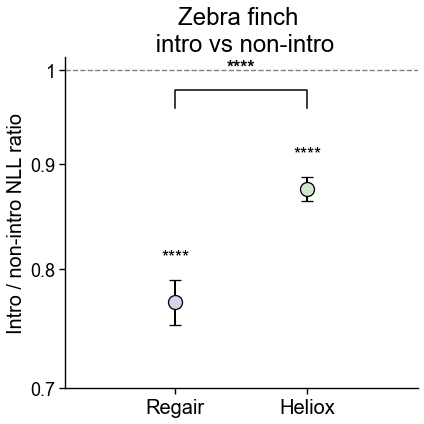

In [9]:
# Cell 9: Fig. 6G
fig, ax = plt.subplots(figsize=(6, 6))
for cond, x in [('regair', -0.15), ('heliox', 0.15)]:
    row = intro_df[intro_df['condition'] == cond].iloc[0]
    ax.errorbar(x, row.ratio, yerr=[[row.ratio - row.ratio_lo], [row.ratio_hi - row.ratio]],
                fmt='o', markersize=14, lw=0, elinewidth=2, capsize=6,
                color=PALE[cond], markeredgecolor='black', markeredgewidth=1.3, ecolor='black')
    star = sig_marker(row.p)
    if star != 'ns':
        ax.text(x, row.ratio_hi * 1.02, star, ha='center', fontsize=18, color='black')
y_top = intro_df['ratio_hi'].max() * 1.08
star = sig_marker(p_intro_interaction)
ax.plot([-0.15, -0.15, 0.15, 0.15], [y_top, y_top * 1.02, y_top * 1.02, y_top], color='black', lw=1.5)
ax.text(0, y_top * 1.04, star, ha='center', fontsize=18, fontweight='bold' if star != 'ns' else 'normal')
ax.axhline(1.0, color='gray', ls='--', lw=1.4)
ax.set_yscale('log')
# explicit ticks rather than set_ratio_ticks: the intro ratio sits well below 1.0 and the
# shared ratio ladder would leave too few labelled values
y_ticks = [0.7, 0.8, 0.9, 1.0]
ax.set_yticks(y_ticks)
ax.set_yticklabels([f'{t:g}' for t in y_ticks])
ax.yaxis.set_minor_locator(mticker.NullLocator())
ax.set_xlim(-0.4, 0.4)
ax.set_xticks([-0.15, 0.15])
ax.set_xticklabels(['Regair', 'Heliox'], fontsize=20)
ax.set_ylabel('Intro / non-intro NLL ratio', fontsize=20)
ax.tick_params(axis='y', labelsize=18)
ax.set_title('Zebra finch \n intro vs non-intro', fontsize=24)
plt.tight_layout()
savefig(fig, 'zf_intro_nonintro_nll_ratio_combined.png')
plt.show()

## 6. Starling k-grams (Fig. 6H and S8E)

NLL inside versus outside the retained k-grams, for k = 3 to 8. Syllable NLL and gap NLL
are each log-transformed, expressed relative to that song's own median, then stacked into
one outcome. `log nll ~ inside + (1 | bird)` is fit per condition and per k; the condition
difference is the interaction in `log nll ~ inside * condition + (1 | bird)`.

In [10]:
# Cell 10: which birds enter, and the log / song-relative transform
sn = D['starling_syllable_nll'].copy()
excluded = meta['params']['KGRAM_NLL_EXCLUDE']
kgram_sets = D['starling_kgram_sets']

# Declared in the build notebook and enforced here: an excluded bird must have no sets in
# the file, and every other bird must have some. Either failure used to pass silently.
set_birds = {b for (b, _, _) in kgram_sets}
if set(excluded) & set_birds:
    raise RuntimeError(f'{sorted(set(excluded) & set_birds)} is excluded but has k-gram sets in the file')
sn = sn[~sn['bird'].isin(list(excluded))].copy()
if set(sn['bird'].unique()) - set_birds:
    raise RuntimeError(f'no k-gram sets for {sorted(set(sn["bird"].unique()) - set_birds)}')
sn['bird_uid'] = sn['bird']
print(f'{sn["bird"].nunique()} birds in the k-gram NLL analysis: {sorted(sn["bird"].unique())}')
for b, why in excluded.items():
    print(f'left out: {b} ({why})')

LOG_FLOOR_PCTILE = 1.0     # values under each bird's 1st percentile of positive NLL are floored


def add_log_col(df, col):
    """log of `col`, with the floor set per bird so that near-zero values (which the log
    would send to large negative numbers) cannot dominate the fit."""
    d = df.copy()
    d[f'log_{col}'] = np.nan
    for bird, idx in d.groupby('bird', observed=True).groups.items():
        vals = pd.to_numeric(d.loc[idx, col], errors='coerce')
        pos = vals[np.isfinite(vals) & (vals > 0)]
        if len(pos) == 0:
            continue
        d.loc[idx, f'log_{col}'] = np.log(vals.clip(lower=float(np.percentile(pos, LOG_FLOOR_PCTILE))))
    return d


def add_song_relative(df, log_col):
    """log NLL minus that song's own median log NLL, which removes song and bird scale
    from within-song contrasts."""
    d = df.copy()
    d[f'{log_col}_rel'] = d[log_col] - d.groupby(['bird', 'cond2', 'basename'],
                                                 observed=True)[log_col].transform('median')
    return d


for col in ['nll_syl', 'nll_gap']:
    sn = add_song_relative(add_log_col(sn, col), f'log_{col}')
REL_SYL, REL_GAP = 'log_nll_syl_rel', 'log_nll_gap_rel'

5 birds in the k-gram NLL analysis: ['s_b1349h_23', 's_b1354_25', 's_b1481h_24', 's_b1484h_24', 's_b1556h_24']
left out: s_b1364_25 (k-gram sets come from a different clustering (s_b1364h_25))


In [11]:
# Cell 11: inside vs outside at every k
def mark_inside(df, motifs, k):
    """True for the first k-1 syllables of every occurrence of a retained k-gram: the
    syllables whose following transition lies inside the sequence. Same rule as the ISI
    analysis."""
    inside = np.zeros(len(df), dtype=bool)
    idx_pos = {ix: i for i, ix in enumerate(df.index)}
    for _, g in df.groupby(['bird', 'basename', 'bout'], sort=False):
        g = g.sort_values('pos')
        labels = g['label'].astype(int).to_numpy()
        ids = g.index.to_numpy()
        for i in range(len(labels) - k + 1):
            if tuple(labels[i:i + k]) in motifs:
                for ix in ids[i:i + k - 1]:
                    inside[idx_pos[ix]] = True
    return inside


def stack_syl_gap(d):
    """Syllable-NLL rows and gap-NLL rows in one long column, each keeping its
    inside/outside label, so both signals feed one estimate."""
    id_cols = ['bird_uid', 'cond2', 'is_inside']
    return pd.concat([d[id_cols].assign(value=d[REL_SYL]), d[id_cols].assign(value=d[REL_GAP])],
                     ignore_index=True).dropna(subset=['value'])


start_panel('Fig 6H / S8E', fits=['k-gram'])
KS = sorted({k for (_, _, k) in kgram_sets})
kgram_rows, interaction_rows = [], []
for k in KS:
    parts = []
    for (bird, cond), g in sn.groupby(['bird', 'cond2'], sort=False):
        motifs = kgram_sets.get((bird, cond, k), set())
        if not motifs:
            continue
        g = g.copy()
        g['is_inside'] = mark_inside(g, motifs, k).astype(int)
        parts.append(g)
    stack = stack_syl_gap(pd.concat(parts))
    stack = stack[np.isfinite(stack['value'])]
    stack['is_heliox'] = (stack['cond2'] == 'heliox').astype(int)

    for cond in COND_ORDER:
        d = stack[stack['cond2'] == cond]
        if d['is_inside'].nunique() < 2:
            print(f'k={k} {cond}: syllables fall on one side only, no ratio')
            continue
        fit = fit_lme('value ~ is_inside', d, d['bird_uid'].astype(str), f'k-gram k={k} {cond}',
                      reml=False, method='lbfgs', disp=False)
        b, se = float(fit.params['is_inside']), float(fit.bse['is_inside'])
        kgram_rows.append(dict(k=k, condition=cond, beta=b, se=se, z=float(fit.tvalues['is_inside']),
                               p=float(fit.pvalues['is_inside']), ratio=np.exp(b),
                               ratio_lo=np.exp(b - 1.96 * se), ratio_hi=np.exp(b + 1.96 * se),
                               n_obs=len(d), n_birds=d['bird_uid'].nunique()))
    fit = fit_lme('value ~ is_inside * is_heliox', stack, stack['bird_uid'].astype(str),
                  f'k-gram k={k} interaction', reml=False, method='lbfgs', disp=False)
    interaction_rows.append(dict(k=k, p_interaction=float(fit.pvalues['is_inside:is_heliox'])))

kgram_df = pd.DataFrame(kgram_rows)
kgram_int = pd.DataFrame(interaction_rows).set_index('k')
# Benjamini-Hochberg across the six sequence lengths, as stated in Methods
kgram_int['q_BH'] = multipletests(kgram_int['p_interaction'], method='fdr_bh')[1]

for r in kgram_df.itertuples():
    record('Fig 6H / S8E', 'starling', f'inside / outside ratio, k={r.k}, {r.condition}',
           beta=r.beta, se=r.se, z=r.z, p=r.p, ratio=r.ratio, ratio_lo=r.ratio_lo,
           ratio_hi=r.ratio_hi, n_obs=r.n_obs, n_birds=r.n_birds)
for k, r in kgram_int.iterrows():
    record('Fig 6H / S8E', 'starling', f'condition x inside interaction, k={k}', p=r['p_interaction'])
    record('Fig 6H / S8E', 'starling', f'condition x inside interaction, BH-adjusted, k={k}', p=r['q_BH'])

print(kgram_df[['k', 'condition', 'ratio', 'ratio_lo', 'ratio_hi', 'beta', 'se', 'z', 'p',
                'n_obs', 'n_birds']].round(4).to_string(index=False))
print('\ncondition x inside interaction:')
print(kgram_int.round(4).to_string())

 k condition  ratio  ratio_lo  ratio_hi    beta     se       z      p  n_obs  n_birds
 3    regair 0.9488    0.9137    0.9852 -0.0526 0.0192 -2.7339 0.0063  10525        5
 3    heliox 0.9337    0.9161    0.9516 -0.0686 0.0097 -7.0817 0.0000  26316        5
 4    regair 0.9051    0.8768    0.9343 -0.0997 0.0162 -6.1584 0.0000  10525        5
 4    heliox 0.9560    0.9392    0.9731 -0.0450 0.0091 -4.9622 0.0000  26316        5
 5    regair 0.8923    0.8644    0.9211 -0.1139 0.0162 -7.0316 0.0000  10525        5
 5    heliox 0.9743    0.9552    0.9937 -0.0261 0.0101 -2.5886 0.0096  26316        5
 6    regair 0.8993    0.8696    0.9300 -0.1062 0.0171 -6.1947 0.0000  10525        5
 6    heliox 0.9669    0.9466    0.9876 -0.0337 0.0108 -3.1149 0.0018  26316        5
 7    regair 0.9282    0.8948    0.9628 -0.0745 0.0187 -3.9932 0.0001  10525        5
 7    heliox 0.9615    0.9407    0.9829 -0.0392 0.0112 -3.5052 0.0005  26316        5
 8    regair 0.9156    0.8776    0.9553 -0.0882 0.0216

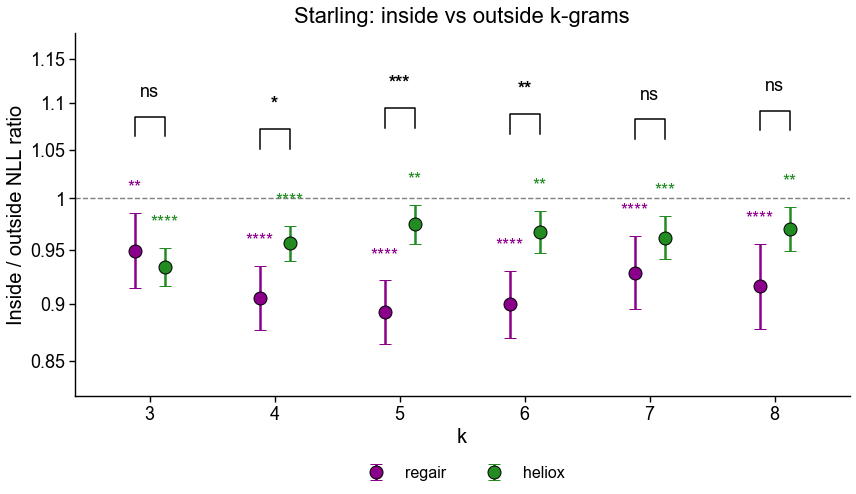

In [12]:
# Cell 12: S8E, all sequence lengths
fig, ax = plt.subplots(figsize=(12, 7))
for cond, off in [('regair', -0.12), ('heliox', 0.12)]:
    s = kgram_df[kgram_df['condition'] == cond].sort_values('k')
    ax.errorbar(s['k'] + off, s['ratio'], yerr=[s['ratio'] - s['ratio_lo'], s['ratio_hi'] - s['ratio']],
                fmt='o', markersize=13, lw=0, elinewidth=2.5, capsize=6,
                color=DARK[cond], markeredgecolor='black', label=cond)
    for _, row in s.iterrows():
        star = p_to_stars(row['p'])
        if star:
            ax.text(row['k'] + off, row['ratio_hi'] * 1.02, star, ha='center', fontsize=18, color=DARK[cond])
y_max_per_k = kgram_df.groupby('k')['ratio_hi'].max()
for k in KS:
    star = p_to_stars(kgram_int.loc[k, 'p_interaction']) or 'ns'
    y_top = y_max_per_k[k] * 1.08
    ax.plot([k - 0.12, k - 0.12, k + 0.12, k + 0.12], [y_top, y_top * 1.02, y_top * 1.02, y_top],
            color='black', lw=1.5)
    ax.text(k, y_top * 1.04, star, ha='center', fontsize=18, fontweight='bold' if star != 'ns' else 'normal')
ax.axhline(1.0, color='gray', ls='--', lw=1.4)
ax.set_yscale('log')
ax.set_xticks(KS)
ax.set_xlim(min(KS) - 0.6, max(KS) + 0.6)
ax.set_ylim(0.82, 1.18)
set_ratio_ticks(ax)      # after set_ylim, since it reads the limits
ax.set_xlabel('k', fontsize=20)
ax.set_ylabel('Inside / outside NLL ratio', fontsize=20)
ax.tick_params(axis='both', labelsize=18)
ax.set_title('Starling: inside vs outside k-grams', fontsize=22, pad=10)
ax.legend(frameon=False, fontsize=16, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout()
savefig(fig, 'q3_kgram_inside_outside_nll_combined_k3to6.png')
plt.show()

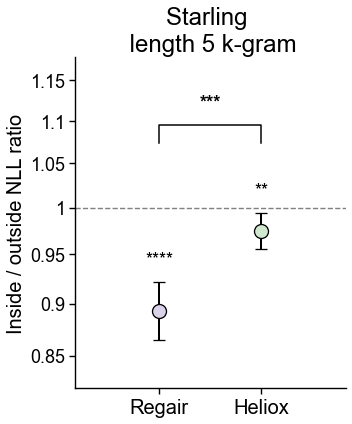

In [13]:
# Cell 13: Fig. 6H, the k = 5 panel
K_VAL = 5
d_plot = kgram_df[kgram_df['k'] == K_VAL]
fig, ax = plt.subplots(figsize=(5, 6))
for cond, x in [('regair', -0.15), ('heliox', 0.15)]:
    row = d_plot[d_plot['condition'] == cond].iloc[0]
    ax.errorbar(x, row.ratio, yerr=[[row.ratio - row.ratio_lo], [row.ratio_hi - row.ratio]],
                fmt='o', markersize=14, lw=0, elinewidth=2, capsize=6,
                color=PALE[cond], markeredgecolor='black', markeredgewidth=1.3, ecolor='black')
    star = p_to_stars(row.p)
    if star:
        ax.text(x, row.ratio_hi * 1.02, star, ha='center', fontsize=18, color='black')
star = p_to_stars(kgram_int.loc[K_VAL, 'p_interaction']) or 'ns'
y_top = d_plot['ratio_hi'].max() * 1.08
ax.plot([-0.15, -0.15, 0.15, 0.15], [y_top, y_top * 1.02, y_top * 1.02, y_top], color='black', lw=1.5)
ax.text(0, y_top * 1.04, star, ha='center', fontsize=18, fontweight='bold' if star != 'ns' else 'normal')
ax.axhline(1.0, color='gray', ls='--', lw=1.4)
ax.set_yscale('log')
ax.set_xlim(-0.4, 0.4)
ax.set_ylim(0.82, 1.18)
set_ratio_ticks(ax)
ax.set_xticks([-0.15, 0.15])
ax.set_xticklabels(['Regair', 'Heliox'], fontsize=20)
ax.set_ylabel('Inside / outside NLL ratio', fontsize=20)
ax.tick_params(axis='y', labelsize=18)
ax.set_title(f'Starling \n length {K_VAL} k-gram', fontsize=24)
plt.tight_layout()
savefig(fig, f'q3_kgram_inside_outside_nll_combined_k{K_VAL}.png')
plt.show()

## 7. Acoustic covariates (Fig. 6I)

How much of the condition effect on song-mean NLL is carried by amplitude, spectral entropy
or song duration. One "total" model per species (`nll ~ condition + (1 | bird)`), then
one "direct" model per covariate (`nll ~ condition + covariate + (1 | bird)`), all on the
same songs, so the total is a shared baseline. Amplitude is the mean amplitude of the song's
syllables in dB re full scale, from the recorded audio; it depends on each bird's microphone
gain, so it is centered within bird. Entropy is BioSound's spectral entropy (entS), averaged
over the song's syllables. Entropy and duration are mean-centered.
Percent carried = (total - direct) / total x 100.

In [14]:
# Cell 14: total and direct effects
# Amplitude (the column mean_level_db) replaces the old "Power" covariate, which was not a measure of
# how loud a song was (see Cell L1 of s4_nll_build_data).
# Entropy is BioSound's spectral entropy (entS, the column mean_ent_s, from Cell B1 of s4_nll_build_data).
# To go back to the syllable tables' own spectral_entropy, put 'mean_spectral_entropy' in its place.
COVARIATES = {'mean_level_db': 'Amplitude', 'mean_ent_s': 'Entropy', 'duration_s': 'Duration'}
# Amplitude is in dB re full scale, which depends on each bird's microphone gain, so it is centered
# within bird: only a song's amplitude relative to that bird's other songs enters the model. The other
# two covariates are centered on the species mean, as before.
CENTER_WITHIN_BIRD = {'mean_level_db'}
cov_table = D['song_covariates']
for column, cell in [('mean_level_db', 'L1'), ('mean_ent_s', 'B1')]:
    if column in COVARIATES and column not in cov_table.columns:
        raise KeyError(f'song_covariates has no {column}: rebuild s4_figure_data.pkl with Cell {cell} of s4_nll_build_data')
start_panel('Fig 6I')
print('songs and birds in the shared set:')
print(cov_table.groupby('species').agg(songs=('s4_avg_nll', 'size'),
                                       birds=('bird_uid', 'nunique')).to_string())

med_rows = []
for sp in ['zebra_finch', 'starling']:
    sub = cov_table[cov_table['species'] == sp].copy()
    r_total = fit_lme('s4_avg_nll ~ C(condition, Treatment(reference="regair"))', sub,
                      sub['bird_uid'], f'Fig 6I {sp} total')
    b_tot = r_total.params[CONDITION_KEY]
    n = dict(n_obs=len(sub), n_birds=sub['bird_uid'].nunique())
    # stored regair - heliox like every other table; the panel itself plots heliox - regair
    record('Fig 6I', sp, 'total condition effect', beta=-b_tot, se=r_total.bse[CONDITION_KEY],
           z=-r_total.tvalues[CONDITION_KEY], p=r_total.pvalues[CONDITION_KEY], **n)
    for cov, cov_label in COVARIATES.items():
        center = sub.groupby('bird_uid')[cov].transform('mean') if cov in CENTER_WITHIN_BIRD else sub[cov].mean()
        sub[f'{cov}_c'] = sub[cov] - center
        r_dir = fit_lme(f's4_avg_nll ~ C(condition, Treatment(reference="regair")) + {cov}_c',
                        sub, sub['bird_uid'], f'Fig 6I {sp} direct | {cov_label}')
        b_dir = r_dir.params[CONDITION_KEY]
        pct = 100 * (b_tot - b_dir) / b_tot
        med_rows.append(dict(species=sp, label=cov_label, coef_total=b_tot, coef_direct=b_dir,
                             pct_mediated=pct, covariate_p=r_dir.pvalues[f'{cov}_c'],
                             color=MED_SPECIES_COLORS[sp]))
        record('Fig 6I', sp, f'direct condition effect | {cov_label}', beta=-b_dir,
               se=r_dir.bse[CONDITION_KEY], z=-r_dir.tvalues[CONDITION_KEY],
               p=r_dir.pvalues[CONDITION_KEY], **n)
        record('Fig 6I', sp, f'{cov_label} coefficient', beta=r_dir.params[f'{cov}_c'],
               se=r_dir.bse[f'{cov}_c'], z=r_dir.tvalues[f'{cov}_c'], p=r_dir.pvalues[f'{cov}_c'], **n)
        record('Fig 6I', sp, f'% of condition effect carried by {cov_label}', value=pct)
med_df = pd.DataFrame(med_rows)
print()
print(med_df[['species', 'label', 'coef_total', 'coef_direct', 'pct_mediated', 'covariate_p']]
      .to_string(index=False))

songs and birds in the shared set:
             songs  birds
species                  
starling       941      6
zebra_finch   1153      6

    species     label  coef_total  coef_direct  pct_mediated  covariate_p
zebra_finch Amplitude    0.189160     0.186631      1.337250 3.569997e-01
zebra_finch   Entropy    0.189160     0.195180     -3.182615 1.858876e-01
zebra_finch  Duration    0.189160     0.192243     -1.629514 7.671646e-02
   starling Amplitude    0.025463     0.001594     93.740196 2.421236e-22
   starling   Entropy    0.025463     0.021344     16.174565 5.060293e-08
   starling  Duration    0.025463     0.018853     25.957987 4.134584e-11


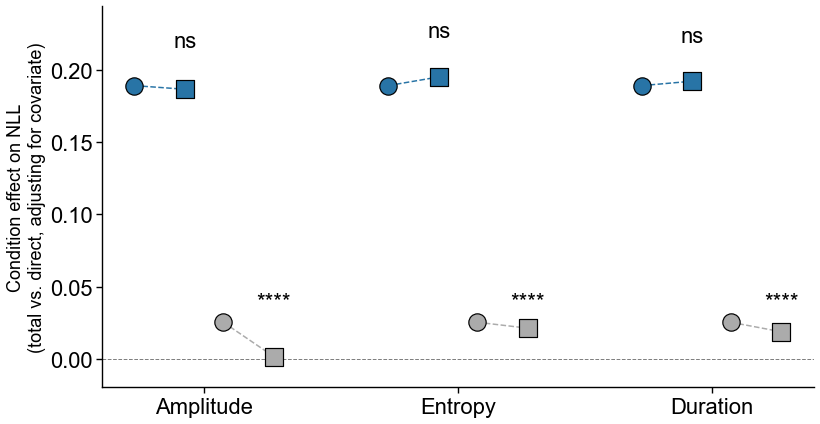

In [15]:
# Cell 15: Fig. 6I
GROUP_SPACING = 2.0     # distance between covariate groups
SPECIES_OFFSET = 0.7    # distance between the two species columns within a group
PAIR_OFFSET = 0.2       # distance between total and direct within a species column

# y limits follow the estimates, with room above for the stars
y_lo = min(0.0, med_df[['coef_total', 'coef_direct']].min().min())
y_hi = max(0.0, med_df[['coef_total', 'coef_direct']].max().max())
y_full = (y_hi - y_lo) or 1.0

fig, ax = plt.subplots(figsize=(11.5, 6))
for gi, cov_label in enumerate(COVARIATES.values()):
    for si, sp in enumerate(['zebra_finch', 'starling']):
        row = med_df[(med_df['label'] == cov_label) & (med_df['species'] == sp)].iloc[0]
        species_x = gi * GROUP_SPACING + (si - 0.5) * SPECIES_OFFSET
        x_tot, x_dir = species_x - PAIR_OFFSET, species_x + PAIR_OFFSET
        ax.scatter(x_tot, row.coef_total, s=300, color=row.color, edgecolor='black',
                   linewidth=1.2, marker='o', zorder=3)
        ax.scatter(x_dir, row.coef_direct, s=300, color=row.color, edgecolor='black',
                   linewidth=1.2, marker='s', zorder=3)
        ax.plot([x_tot, x_dir], [row.coef_total, row.coef_direct], color=row.color,
                linewidth=1.5, linestyle='--', zorder=2)
        # the star reports the covariate's own P value, not the condition effect's
        y_top = max(row.coef_total, row.coef_direct)
        y_span = abs(row.coef_total - row.coef_direct) + 1e-9
        ax.text(x_dir, y_top + 0.1 * max(y_span, abs(y_top)) + 0.04 * y_full, sig_marker(row.covariate_p),
                ha='center', fontsize=22)
ax.axhline(0, color='gray', linestyle='--', linewidth=1.0, zorder=1)
ax.set_xticks([gi * GROUP_SPACING for gi in range(len(COVARIATES))])
ax.set_xticklabels(list(COVARIATES.values()), fontsize=22)
ax.set_ylim(y_lo - 0.10 * y_full, y_hi + 0.25 * y_full)
ax.tick_params(axis='y', labelsize=22)
ax.set_ylabel('Condition effect on NLL\n(total vs. direct, adjusting for covariate)', fontsize=18)
plt.tight_layout()
savefig(fig, 's4_all_confounds_mediation_sharedbaseline.png')
plt.show()

## 8. Silence versus song (S8 A-B)

--- Starling ---
  heliox effect in silence : β=-0.0122, SE=0.0136, z=-0.90, P=3.696e-01
  heliox effect in song    : β=-0.1267, SE=0.0136, z=-9.32, P=1.110e-20
  song vs silence: regair P=7.701e-155, heliox P=0.000e+00
--- Zebra finch ---
  heliox effect in silence : β=-0.1708, SE=0.0114, z=-14.96, P=1.248e-50
  heliox effect in song    : β=-0.2817, SE=0.0114, z=-24.67, P=2.102e-134
  song vs silence: regair P=0.000e+00, heliox P=0.000e+00


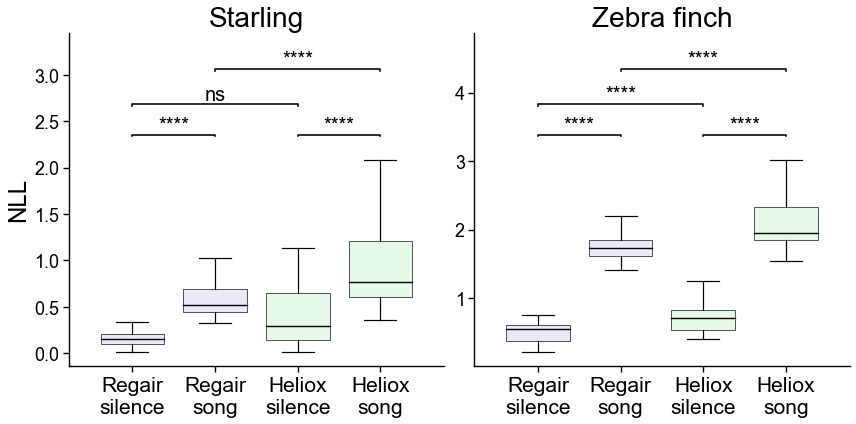

In [16]:
# Cell 16: S8 A-B
region_condition_figure(D['region_nll'], ('silence', 'song'), 'S8 A-B',
                        x_spacing=0.65, filename='s4_silencesong_bothspecies_boxplot.png')

## 9. Peak song NLL and NLL jump rate (S8 C-D)

`metric ~ condition + (1 | bird)`, per species, then refit with song amplitude (the mean
amplitude of the song's syllables, centered within bird) as a covariate.

In [17]:
# Cell 17: models with and without the amplitude covariate
# Amplitude (the column level_db: mean amplitude of the song's syllables, from the recorded audio)
# replaces "power", which was the envelope of a song rescaled to its own peak and so said nothing about
# loudness. Amplitude is centered within bird, since dB re full scale depends on each bird's microphone gain.
start_panel('S8C', 'S8D')
trace = D['song_trace_metrics']
if 'level_db' not in trace.columns:
    raise KeyError('song_trace_metrics has no level_db: rebuild s4_figure_data.pkl with Cell L1 of s4_nll_build_data')
print('birds per species x condition:')
print(trace.groupby(['species', 'condition'])['bird_uid'].nunique().unstack().to_string())

METRICS = {'nll_p100': ('S8C', 'peak song NLL'), 'jump_rate_raw': ('S8D', 'NLL jump rate')}
adj_rows = []
for species in ['starling', 'zebra_finch']:
    for metric, (panel, metric_label) in METRICS.items():
        for cov in [None, 'level_db']:
            sub = trace[(trace['species'] == species) & np.isfinite(trace[metric])].copy()
            sub['cond'] = (sub['condition'] == 'heliox').astype(int)
            formula = f'{metric} ~ cond'
            if cov is not None:
                sub = sub[np.isfinite(sub[cov])].copy()
                sub[f'{cov}_c'] = sub[cov] - sub.groupby('bird_uid')[cov].transform('mean')
                formula += f' + {cov}_c'
            fit = fit_lme(formula, sub, sub['bird_uid'], f'{panel} {species} {"amplitude" if cov else "unadjusted"}',
                          reml=False, method='lbfgs', disp=False)
            # negated into the paper's regair - heliox convention; SE and P are unaffected
            row = dict(beta=-float(fit.params['cond']), se=float(fit.bse['cond']),
                       z=-float(fit.tvalues['cond']), p=float(fit.pvalues['cond']),
                       n_obs=len(sub), n_birds=sub['bird_uid'].nunique())
            adj_rows.append(dict(metric=metric, species=species, covariate='amplitude' if cov else 'none', **row))
            record(panel, species, f'{metric_label}, {"+ amplitude" if cov else "unadjusted"}', **row)
adjustment_df = pd.DataFrame(adj_rows)
print()
print(adjustment_df.round(5).to_string(index=False))

birds per species x condition:
condition    heliox  regair
species                    
starling          6       6
zebra_finch       6       6

       metric     species covariate     beta      se         z       p  n_obs  n_birds
     nll_p100    starling      none -0.15331 0.02869  -5.34295 0.00000    941        6
     nll_p100    starling amplitude -0.07240 0.02767  -2.61635 0.00889    941        6
jump_rate_raw    starling      none -0.01229 0.00647  -1.89903 0.05756    941        6
jump_rate_raw    starling amplitude -0.02155 0.00657  -3.27791 0.00105    941        6
     nll_p100 zebra_finch      none -0.26754 0.01365 -19.59689 0.00000   1153        6
     nll_p100 zebra_finch amplitude -0.26647 0.01419 -18.77294 0.00000   1153        6
jump_rate_raw zebra_finch      none -0.00777 0.00237  -3.28084 0.00103   1153        6
jump_rate_raw zebra_finch amplitude -0.00547 0.00245  -2.23357 0.02551   1153        6


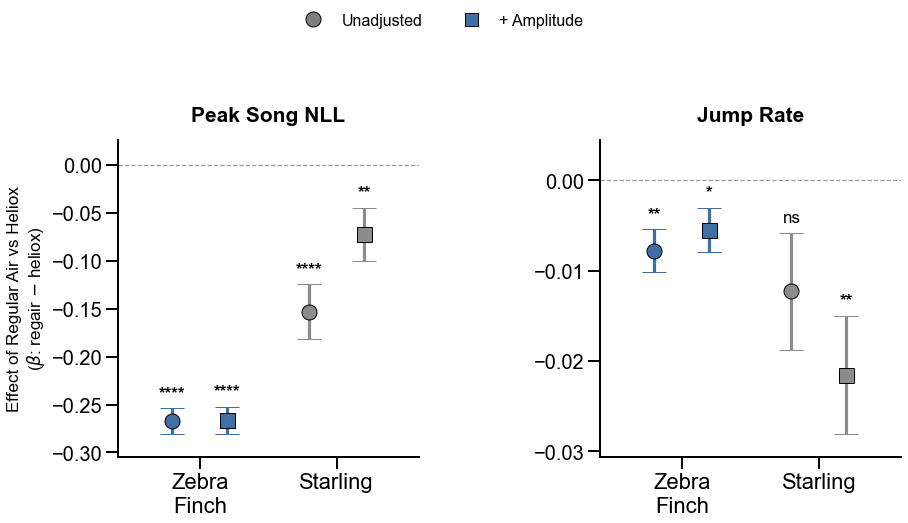

In [18]:
# Cell 18: S8 C-D
with mpl.rc_context({'font.size': 20, 'axes.linewidth': 2.0,
                     'xtick.major.width': 2.0, 'ytick.major.width': 2.0,
                     'xtick.major.size': 12, 'ytick.major.size': 12,
                     'xtick.labelsize': 20, 'ytick.labelsize': 25, 'axes.labelsize': 19}):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    x_positions = {'zebra_finch': 0, 'starling': 1}
    COV_OFFSET = {'none': -0.20, 'amplitude': 0.20}
    COV_MARKER = {'none': 'o', 'amplitude': 's'}

    def draw_adjusted_panel(ax, d, title, min_ymax=None):
        ends = []
        for species, color in PANEL_COLORS.items():
            for cov in ['none', 'amplitude']:
                row = d[(d['species'] == species) & (d['covariate'] == cov)].iloc[0]
                x = x_positions[species] + COV_OFFSET[cov]
                ax.errorbar(x, row['beta'], yerr=row['se'], fmt=COV_MARKER[cov],
                            markerfacecolor=color, markeredgecolor='black', ecolor=color,
                            markeredgewidth=1, capsize=12, markersize=15,
                            elinewidth=3.2, capthick=8, zorder=3)
                ends += [row['beta'] - row['se'], row['beta'] + row['se']]
                star = p_to_stars(row['p'])
                # stars sit above the point rather than under the error bar
                ax.annotate(star if star else 'ns', xy=(x, row['beta'] + row['se']),
                            xytext=(0, 8), textcoords='offset points', ha='center', va='bottom',
                            fontsize=17, fontweight='bold' if star else 'normal')
        ax.axhline(0, color='gray', lw=1.2, ls='--', zorder=0, alpha=0.8)
        ax.set_xlim(-0.6, 1.6)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Zebra\nFinch', 'Starling'], fontsize=22)
        y_min, y_max = min(ends), max(ends)
        span = y_max - y_min if y_max > y_min else abs(y_max) or 1.0
        y_hi = y_max + 0.30 * span      # headroom for the stars sitting above
        if min_ymax is not None:
            y_hi = max(y_hi, min_ymax)
        ax.set_ylim(y_min - 0.10 * span, y_hi)
        ax.set_title(title, fontsize=21, fontweight='bold', pad=18)
        ax.tick_params(axis='y', labelsize=20)

    draw_adjusted_panel(axes[0], adjustment_df[adjustment_df['metric'] == 'nll_p100'],
                        'Peak Song NLL', min_ymax=0.02)
    axes[0].set_ylabel(r'Effect of Regular Air vs Heliox' '\n' r'($\beta$: regair $-$ heliox)', fontsize=17)
    draw_adjusted_panel(axes[1], adjustment_df[adjustment_df['metric'] == 'jump_rate_raw'], 'Jump Rate')
    legend_handles = [
        plt.Line2D([0], [0], marker='o', color='black', linestyle='', markersize=15,
                   markerfacecolor='gray', markeredgecolor='black', label='Unadjusted'),
        plt.Line2D([0], [0], marker='s', color='black', linestyle='', markersize=13,
                   markerfacecolor=PANEL_COLORS['zebra_finch'], markeredgecolor='black', label='+ Amplitude'),
    ]
    fig.legend(handles=legend_handles, loc='upper center', ncol=2, frameon=False,
               bbox_to_anchor=(0.5, 1.06), fontsize=16)
    plt.subplots_adjust(left=0.22, wspace=0.6, top=0.78, bottom=0.15)
    savefig(fig, 's4_heliox_maxNLL_jumprate_vertical_leveladj.png')
    plt.show()

## 10. Statistics table
Every number recorded above, in one table, saved as `s4_nll_statistics.csv`. 

In [19]:
# Cell 19: the statistics table
stats_table = pd.DataFrame(STATS)
cols = ['panel', 'species', 'quantity', 'beta', 'se', 'z', 'p', 'ratio', 'ratio_lo', 'ratio_hi',
        'value', 'n_obs', 'n_birds']
stats_table = stats_table.reindex(columns=cols)
stats_path = os.path.join(FIG_DIR, 's4_nll_statistics.csv')
stats_table.to_csv(stats_path, index=False)
print(f'{len(stats_table)} rows saved to {stats_path}')

fit_log = pd.DataFrame(FIT_LOG)
flagged = fit_log[(~fit_log['converged']) | (fit_log['bird_variance'] < 1e-10)]
# print(f'\n{len(fit_log)} models fit; {len(flagged)} did not converge or put the bird variance at zero:')
# if len(flagged):
#     print(flagged.to_string(index=False))


# with pd.option_context('display.width', 250, 'display.max_rows', 500, 'display.max_colwidth', 70):
#     print()
#     print(stats_table.to_string(index=False, float_format=lambda v: f'{v:.5g}'))

66 rows saved to /mnt/cube/lstanwic/umap_avgn_shared/lauren_umap/heliox_processing/notebooks/for_github/figures/s4_nll_statistics.csv
